In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [31]:
df = pd.read_csv('data/Mall_Customers.csv')

In [32]:
#X = df.drop(columns='CustomerID')
X = df[['Annual Income (k$)','Spending Score (1-100)']]

In [33]:
#X['Genre'] = X['Genre'].map({'Male':0, 'Female':1})

In [34]:
X

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40
...,...,...
195,120,79
196,126,28
197,126,74
198,137,18


In [41]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X = pd.DataFrame(data = X_scaled, columns = X.columns)

,Annual Income (k$),Spending Score (1-100),Cluster
0,-1.738999,-0.434801,1.798458
1,-1.738999,1.195704,0.415029
2,-1.700830,-1.715913,1.798458
3,-1.700830,1.040418,0.415029
4,-1.662660,-0.395980,1.798458
...,...,...,...
195,2.268791,1.118061,-0.276686
196,2.497807,-0.861839,1.106743
197,2.497807,0.923953,-0.276686
198,2.917671,-1.250054,1.106743


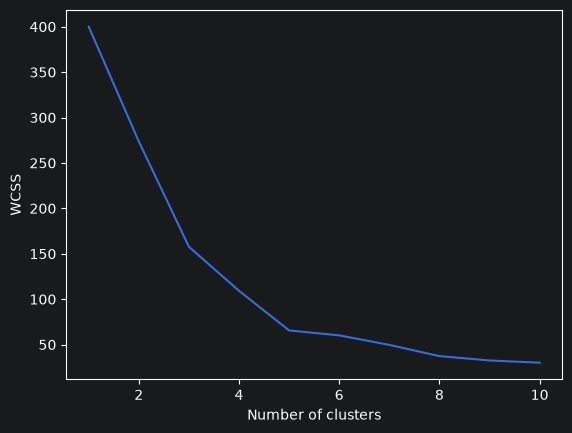

In [36]:
from sklearn.cluster import KMeans
wcss = []
for i in range(1,11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

plt.plot(range(1,11),wcss)
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.show()

In [37]:
kmeans = KMeans(n_clusters=5, init='k-means++', random_state=42)


In [38]:
y_kmeans = kmeans.fit_predict(X)

In [42]:
X['Cluster'] = y_kmeans
X

,Annual Income (k$),Spending Score (1-100),Cluster
0,-1.738999,-0.434801,4
1,-1.738999,1.195704,2
2,-1.700830,-1.715913,4
3,-1.700830,1.040418,2
4,-1.662660,-0.395980,4
...,...,...,...
195,2.268791,1.118061,1
196,2.497807,-0.861839,3
197,2.497807,0.923953,1
198,2.917671,-1.250054,3


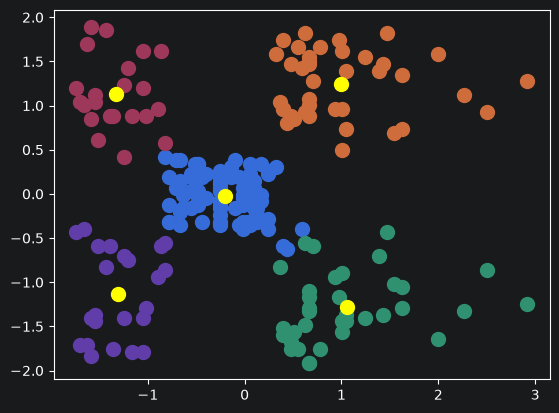

In [49]:
cluster_0 = X[X['Cluster'] == 0]
cluster_1 = X[X['Cluster'] == 1]
cluster_2 = X[X['Cluster'] == 2]
cluster_3 = X[X['Cluster'] == 3]
cluster_4 = X[X['Cluster'] == 4]
plt.scatter(cluster_0['Annual Income (k$)'], cluster_0['Spending Score (1-100)'],s = 100,label='Cluster 1')
plt.scatter(cluster_1['Annual Income (k$)'], cluster_1['Spending Score (1-100)'],s = 100,label='Cluster 2')
plt.scatter(cluster_2['Annual Income (k$)'], cluster_2['Spending Score (1-100)'],s = 100,label='Cluster 3')
plt.scatter(cluster_3['Annual Income (k$)'], cluster_3['Spending Score (1-100)'],s = 100,label='Cluster 4')
plt.scatter(cluster_4['Annual Income (k$)'],cluster_4['Spending Score (1-100)'],s = 100,label='Cluster 5')
plt.scatter(kmeans.cluster_centers_[:,0],kmeans.cluster_centers_[:,1],s=100, c = 'yellow', label = 'Centroids')